# 함정 5. 범위를 관측하기 전에 양자화를 켜면 생기는 일

## EMA가 범위 변화를 따라가는 시간

observer를 [−1,1]로 초기화한 뒤 [−2,2]를 반복 관측한다. c=0.01을 고정하고 스텝에 따른 클립 값과 초기 범위의 잔여 영향을 기록한다. 첫 배치는 즉시 초기화되며 이후부터 EMA를 적용한다.

반감기는 약 69스텝, 95% 도달 시간은 약 298스텝이다. 연속 계산값 298.073을 반올림하면 298이며, 95% 이상을 만족하는 최초의 정수 스텝은 299다. 기존 기대값 1.95와 허용 오차는 그대로 유지한다.

시드 0 하나로 실행한다. [학습 가이드](../docs/README.md#함정-5-범위를-관측하기-전에-양자화를-켜면-생기는-일).


In [1]:
import json
import os
import platform
import random
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
RESULTS = ROOT / "runs" / "m2"
FIGURES = ROOT / "docs" / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(RESULTS / ".matplotlib"))

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(device=DEVICE).manual_seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "svg.fonttype": "none", "svg.hashsalt": "quant-pitfalls"})
RUN_INFO = {"seed": SEED, "seeds": 1, "python": platform.python_version(), "torch": torch.__version__, "device": DEVICE,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None, "runtime_seconds": None}
STARTED = time.monotonic()
run_display = display(RUN_INFO, display_id=True)


{'seed': 0,
 'seeds': 1,
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.861}

In [2]:
from copy import deepcopy
from quant_pitfalls.quant.fake_quant import FakeQuantize
from quant_pitfalls.quant.observer import EMAMinMaxObserver
from quant_pitfalls.quant.uniform import UniformSpec

c = 0.01
obs = EMAMinMaxObserver(c).to(DEVICE)
obs(torch.tensor([-1, 1], device=DEVICE, dtype=torch.float64))
clips = [float(obs.clip())]
for _ in range(400):
    obs(torch.tensor([-2, 2], device=DEVICE, dtype=torch.float64))
    clips.append(float(obs.clip()))
steps = np.arange(len(clips))
clips = np.array(clips)
residual = 2 - clips
theoretical = (1 - c)**steps
np.testing.assert_allclose(residual, theoretical, rtol=1e-11, atol=1e-13)
continuous_half = float(np.log(2) / -np.log(1 - c))
continuous_95 = float(np.log(20) / -np.log(1 - c))
first_half = int(np.flatnonzero(clips >= 1.5)[0])
first_95 = int(np.flatnonzero(clips >= 1.95)[0])
print(f"Half-life: {continuous_half:.6f}; first integer crossing: {first_half}; clip at step 69: {clips[69]:.9f}")
print(f"95% time: {continuous_95:.6f}; first integer crossing: {first_95}; clip at step 298: {clips[298]:.9f}")


Half-life: 68.967564; first integer crossing: 69; clip at step 69: 1.500162970
95% time: 298.072852; first integer crossing: 299; clip at step 298: 1.949963377


## 독립 스위치 검증

같은 관측 상태에서 observer와 fake-quant를 각각 켜고 끈다. 둘 다 끄면 항등이고, observer만 켜면 범위만 바뀐다. fake-quant만 켜면 기존 범위를 사용한다. 아래는 기능 검증이며 학습 손실 비교가 아니다.


{'observe': False, 'fake_quant': False, 'alpha': 1.0, 'identity': True, 'output': [-1.4, -0.2, 0.2, 1.4]}
{'observe': True, 'fake_quant': False, 'alpha': 1.004, 'identity': True, 'output': [-1.4, -0.2, 0.2, 1.4]}
{'observe': False, 'fake_quant': True, 'alpha': 1.0, 'identity': False, 'output': [-1.0, -0.14285714285714285, 0.14285714285714285, 1.0]}
{'observe': True, 'fake_quant': True, 'alpha': 1.004, 'identity': False, 'output': [-1.004, -0.14342857142857143, 0.14342857142857143, 1.004]}


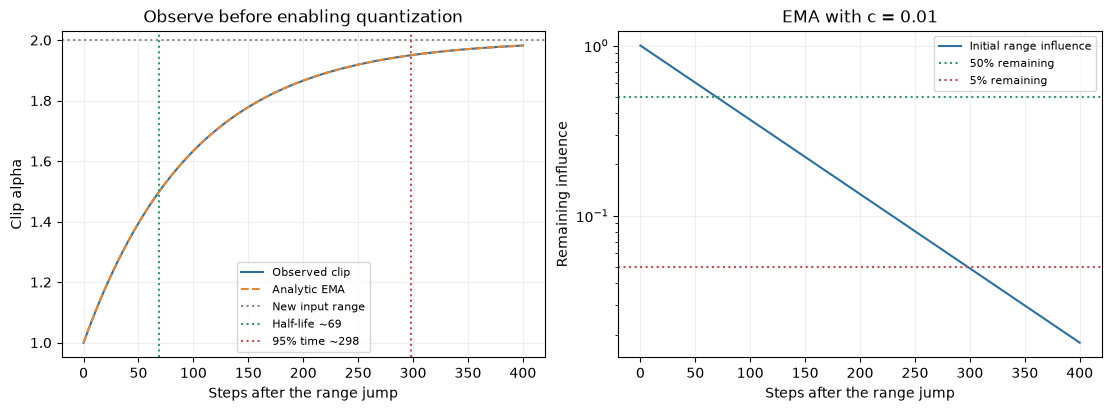

In [3]:
base = FakeQuantize(UniformSpec(4)).to(DEVICE, dtype=torch.float64)
base(torch.tensor([-1, 1], device=DEVICE, dtype=torch.float64))
probe = torch.tensor([-1.4, -0.2, 0.2, 1.4], device=DEVICE, dtype=torch.float64)
controls = []
for observe, quantize in [(False, False), (True, False), (False, True), (True, True)]:
    fq = deepcopy(base)
    fq.enable_observer(observe)
    fq.enable_fake_quant(quantize)
    out = fq(probe)
    row = {"observe": observe, "fake_quant": quantize, "alpha": float(fq.alpha), "identity": torch.equal(out, probe), "output": out.tolist()}
    controls.append(row)
    print(row)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(steps, clips, color="#2E6F9E", label="Observed clip")
axes[0].plot(steps, 2 - theoretical, "--", color="#E68735", label="Analytic EMA")
axes[0].axhline(2, color="#888888", linestyle=":", label="New input range")
for step, label, color in [(69, "Half-life ~69", "#38936F"), (298, "95% time ~298", "#B74D56")]:
    axes[0].axvline(step, linestyle=":", color=color, label=label)
axes[0].set(xlabel="Steps after the range jump", ylabel="Clip alpha", title="Observe before enabling quantization")
axes[0].legend(fontsize=8)
axes[1].semilogy(steps, residual, color="#2E6F9E", label="Initial range influence")
axes[1].axhline(0.5, color="#38936F", linestyle=":", label="50% remaining")
axes[1].axhline(0.05, color="#B74D56", linestyle=":", label="5% remaining")
axes[1].set(xlabel="Steps after the range jump", ylabel="Remaining influence", title="EMA with c = 0.01")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(FIGURES / "05_observe-before-quant.svg", metadata={"Date": None})
fig.savefig(RESULTS / "05_observe-before-quant.png", dpi=140)
plt.show()
report = {"averaging_constant": c, "continuous_half_life": continuous_half, "continuous_95_time": continuous_95,
          "first_integer_half_step": first_half, "first_integer_95_step": first_95, "clip_at_69": float(clips[69]),
          "clip_at_298": float(clips[298]), "controls": controls, "curve": {"steps": steps.tolist(), "clips": clips.tolist()}}


In [4]:
if DEVICE == "cuda":
    torch.cuda.synchronize()
report["run"] = {**RUN_INFO, "runtime_seconds": round(time.monotonic() - STARTED, 3)}
(RESULTS / "05_observe-before-quant.json").write_text(json.dumps(report, indent=2) + "\n")
run_display.update(report["run"])
print("Saved results: runs/m2/05_observe-before-quant.json")


Saved results: runs/m2/05_observe-before-quant.json


## 관측 워밍업과 학습 손실

같은 float 체크포인트에서 관측 워밍업 후 양자화, 처음부터 관측·양자화, 관측 없이 기본 스케일 양자화를 비교한다. 세 시드의 처음 1,000스텝 손실·클리핑 비율·BN 통계 기록을 사용한다.

기본 재현 명령은 저장소의 측정 기록을 사용한다. 새로운 학습 결과를 만들려면 [재현 방법](../docs/reproduction.md)의 체크포인트·학습 모드를 참고한다.


In [5]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.025,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


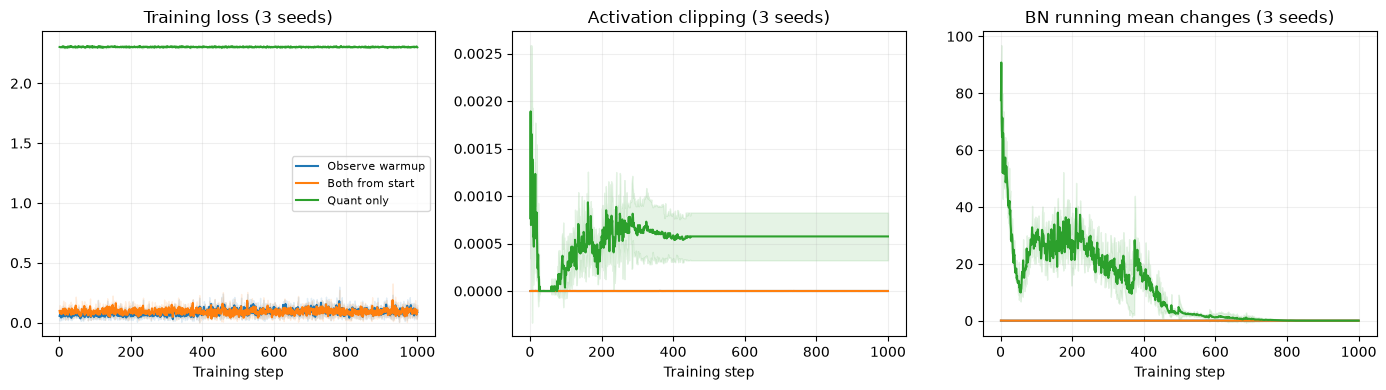

In [6]:
if READY:
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    for method,label in (('warmup','Observe warmup'),('both','Both from start'),('quant-only','Quant only')):
        histories=[REPORT['reports'][f'nb05-{method}-s{s}']['diagnostics'] for s in (0,1,2)]
        for ax,key,title in zip(axes,('loss','activation_clipping_fraction','bn_mean_change_l2'),('Training loss','Activation clipping','BN running mean changes')):
            curves=np.array([[h[key] for h in items] for items in histories])
            mean,std=curves.mean(0),curves.std(0,ddof=1)
            x=np.arange(1,len(mean)+1)
            line=ax.plot(x,mean,label=label)[0]
            ax.fill_between(x,mean-std,mean+std,color=line.get_color(),alpha=.12)
            ax.set_title(title+' (3 seeds)')
            ax.set_xlabel('Training step')
            ax.grid(alpha=.2)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig,'05_observer-training')

In [7]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

입력 범위 변화를 고정하고 EMA 계수 c를 0.005와 0.02로 바꿔 보자. 수식으로 예측한 반감기를 관측 곡선에서 확인하자.
